# SEMMA — Red wine quality regression

CMPE-255 • Data mining process assignment • November 3, 2026

Run all cells in order. This notebook is self-contained and Colab-compatible. It uses the bundled CSV when present; otherwise it downloads the exact public Kaggle dataset and checks its SHA-256. Figures, fitted pipelines, and evaluation tables are written to `artifacts/`. Results stored in this notebook were executed locally; a hosted Colab run remains a separate verification. AI assistance: Codex; see the review record and student verification checklist.

## Setup
A CPU runtime is sufficient. In a fresh Colab runtime, run the optional installation cell, then restart the runtime if an installed library was already imported. Pinned dependencies match the verified local run. No API key is required.

In [1]:
# Optional fresh-runtime installation (uncomment if needed):
# %pip install numpy==2.0.2 pandas==2.3.3 scikit-learn==1.6.1 matplotlib==3.9.4 joblib==1.5.3 requests==2.32.5 tabulate==0.9.0

In [2]:
from pathlib import Path
import io, json, hashlib, zipfile, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib, requests
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.metrics import *
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (9,5), 'axes.spines.top':False, 'axes.spines.right':False})
ART = Path('artifacts'); ART.mkdir(exist_ok=True)
def save_json(name, value):
    (ART/name).write_text(json.dumps(value, indent=2, default=lambda x: x.item() if hasattr(x,'item') else str(x)))
def figure(name):
    plt.tight_layout(); plt.savefig(ART/name, dpi=150, bbox_inches='tight'); plt.show(); plt.close()
def load_kaggle(slug, filename, expected):
    path = Path('data')/filename
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        response=requests.get('https://www.kaggle.com/api/v1/datasets/download/'+slug, timeout=120)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as z:
            matches=[n for n in z.namelist() if Path(n).name == filename]
            if len(matches)!=1: raise ValueError('Expected exactly one matching CSV in archive')
            path.write_bytes(z.read(matches[0]))
    actual=hashlib.sha256(path.read_bytes()).hexdigest()
    assert actual == expected, 'Dataset version changed; inspect before continuing'
    print('Verified SHA-256:',actual)
    return pd.read_csv(path)
def quality_report(df):
    out=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'unique':df.nunique()})
    out.to_csv(ART/'data_quality.csv'); display(out)
    print('Rows:',len(df),'Exact duplicates:',int(df.duplicated().sum()))
def bootstrap_ci(y, pred, metric, n=500):
    rng=np.random.default_rng(SEED); y=np.asarray(y); pred=np.asarray(pred); vals=[]
    for _ in range(n):
        ix=rng.integers(0,len(y),len(y))
        try: vals.append(metric(y[ix],pred[ix]))
        except ValueError: pass
    return np.quantile(vals,[.025,.975]).tolist()
save_json('environment.json',{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scikit_learn':sklearn.__version__,'seed':SEED})


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Project context
A hypothetical lab wants a numerical estimate of a sensory quality score from measured chemistry to support review scheduling. Predictions are not a replacement for tasting or product-release decisions. The predeclared technical target is at least a 10% reduction in test RMSE relative to the training-mean baseline. This target is an assumed course-project criterion.

SEMMA organizes the analysis as Sample, Explore, Modify, Model, Assess. Business context and a delivery plan are included as extensions rather than relabeling them as extra SEMMA stages. The implementation is Python; no SAS execution is claimed. See `sas_mapping.md` for an optional Enterprise Miner replication path.

## 1. Sample
### Source, population, unit, sample design, and partitioning
Use [Kaggle Red Wine Quality](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009), attributed to Cortez et al. A row describes a red wine with 11 physicochemical measurements and a sensory quality score. The sample does not establish representativeness of all wines, countries or harvests.

The dataset is small, so use all eligible unique observations rather than subsampling for speed. Remove exact duplicate rows and record the count. Identical chemistry rows receive the same group identifier even when labels differ. Group-aware 60/20/20 splitting prevents those predictor profiles from appearing on both sides of an evaluation. Cross-validation uses the same grouping principle. Batch/producer identifiers are unavailable, so group independence is still not guaranteed.

In [3]:
raw=load_kaggle('uciml/red-wine-quality-cortez-et-al-2009','winequality-red.csv','d6a0d9bd24806944818795f22500c46cb6424cbff517aacda36595d3ed9b2daa')
quality_report(raw)
df=raw.drop_duplicates().copy(); features=[c for c in df if c!='quality']; X=df[features]; y=df.quality
assert np.isfinite(df.to_numpy()).all() and y.between(0,10).all()
assert (X>=0).all().all()
groups=pd.util.hash_pandas_object(X,index=False)
tr,rest=next(GroupShuffleSplit(n_splits=1,test_size=.4,random_state=SEED).split(X,y,groups))
va0,te0=next(GroupShuffleSplit(n_splits=1,test_size=.5,random_state=SEED).split(X.iloc[rest],y.iloc[rest],groups.iloc[rest]))
va,te=rest[va0],rest[te0]
assert not(set(groups.iloc[tr])&set(groups.iloc[va]) or set(groups.iloc[tr])&set(groups.iloc[te]) or set(groups.iloc[va])&set(groups.iloc[te]))
Xtr,Xv,Xte=X.iloc[tr],X.iloc[va],X.iloc[te];ytr,yv,yte=y.iloc[tr],y.iloc[va],y.iloc[te]
part=np.full(len(df),'train',dtype=object);part[va]='validation';part[te]='test'
pd.DataFrame({'source_row':df.index,'feature_group':groups.to_numpy(),'partition':part}).to_csv(ART/'split_manifest.csv',index=False)
save_json('sample_audit.json',{'raw_n':len(raw),'unique_n':len(df),'exact_duplicates_removed':len(raw)-len(df),'n_train':len(tr),'n_validation':len(va),'n_test':len(te),'feature_groups':groups.nunique()})
display(pd.crosstab(pd.Series(part),pd.Series(y.to_numpy())))


Verified SHA-256: d6a0d9bd24806944818795f22500c46cb6424cbff517aacda36595d3ed9b2daa


,dtype,missing,unique
fixed acidity,float64,0,96
volatile acidity,float64,0,143
citric acid,float64,0,80
residual sugar,float64,0,91
chlorides,float64,0,153
free sulfur dioxide,float64,0,60
total sulfur dioxide,float64,0,144
density,float64,0,436
pH,float64,0,89
sulphates,float64,0,96


Rows: 1599 Exact duplicates: 240


col_0,3,4,5,6,7,8
row_0,,,,,,
test,3,14,107,102,44,2
train,5,31,361,321,87,10
validation,2,8,109,112,36,5


## 2. Explore
### Expected relationships, unexpected patterns, and anomalies
Inspect the training quality distribution, chemistry histograms, pairwise correlations and skewness. Hypotheses include an association between alcohol and sensory score, but they are observational. Extreme measurements are inspected rather than automatically removed: a large residual sugar or sulphate value may be a valid wine. Correlated measurements can make linear coefficients unstable and permutation importance diffuse. The scoring scale is ordinal; numerical regression assumes roughly equal distances between adjacent scores and that assumption must be disclosed.

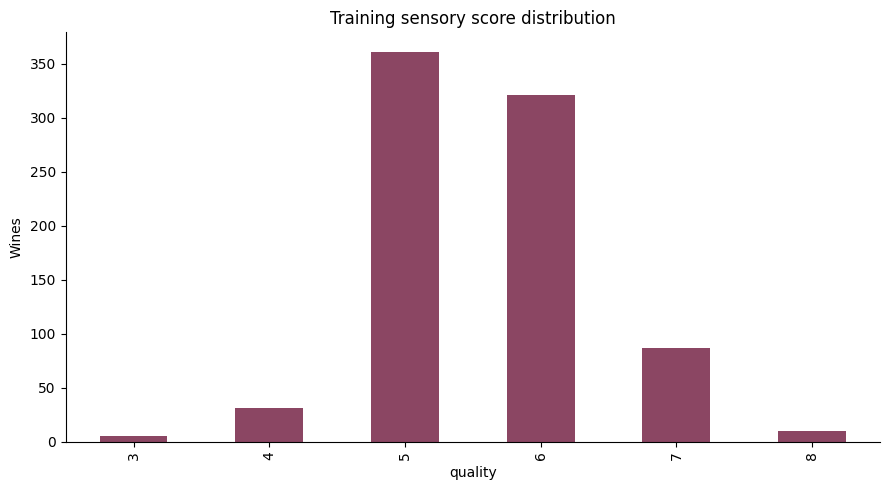

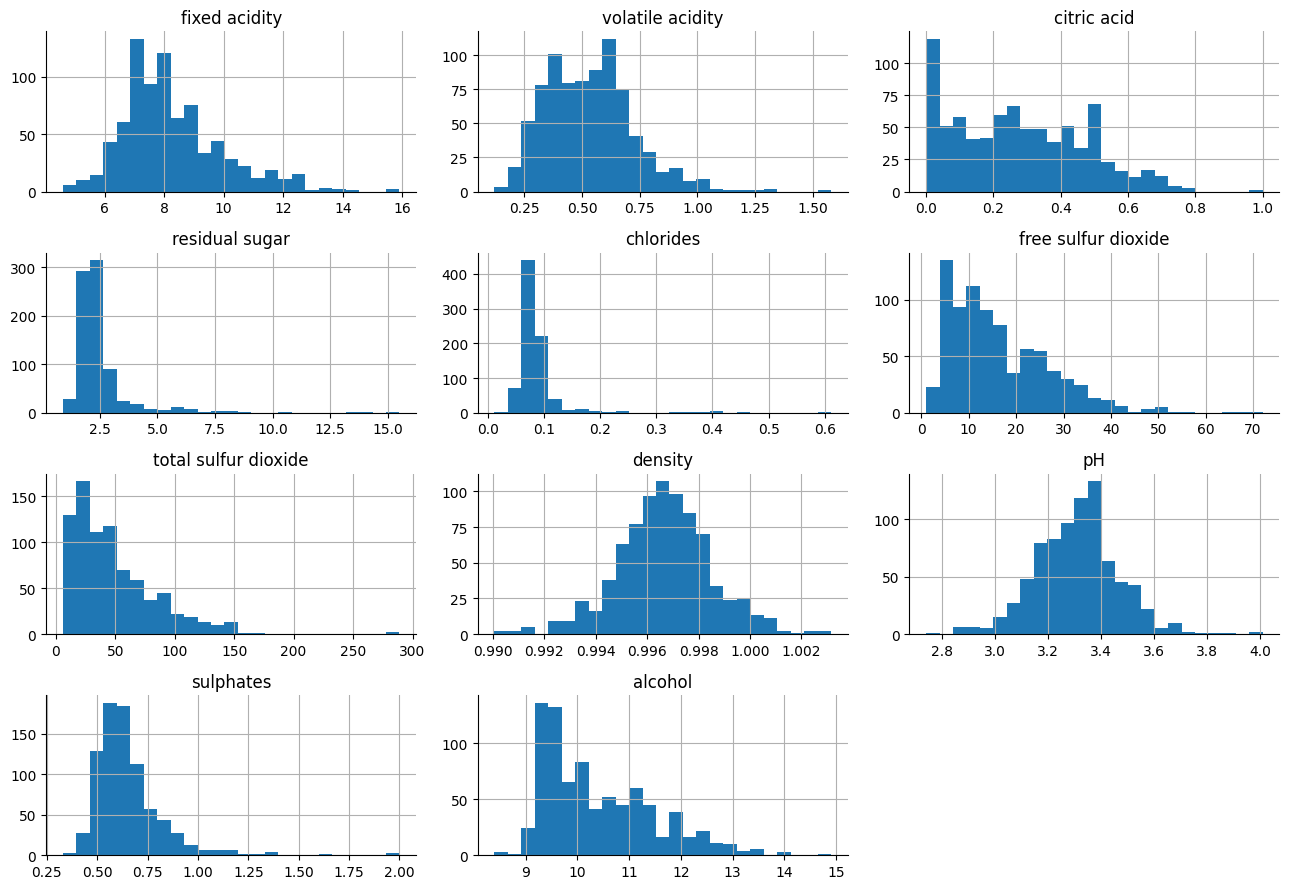

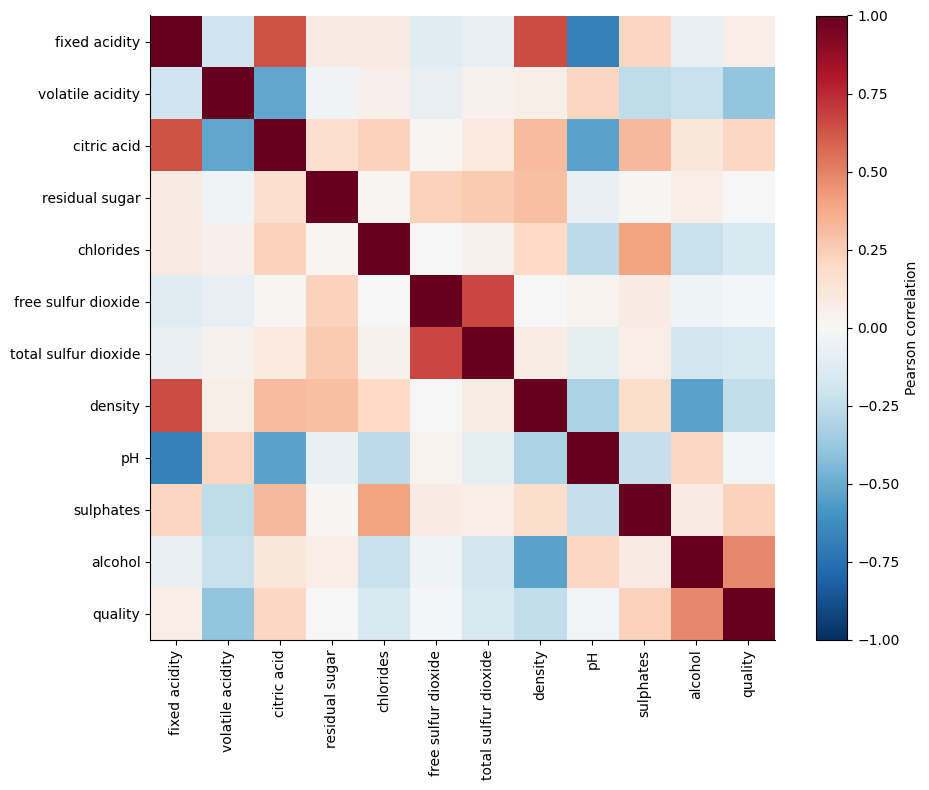

,skew,min,median,max,quality_correlation
fixed acidity,0.967947,4.60000,7.9000,15.90000,0.063303
volatile acidity,0.808937,0.12000,0.5200,1.58000,-0.398310
citric acid,0.368885,0.00000,0.2500,1.00000,0.209052
residual sugar,4.654091,0.90000,2.2000,15.50000,0.005451
chlorides,5.890955,0.01200,0.0790,0.61100,-0.155230
free sulfur dioxide,1.232022,1.00000,14.0000,72.00000,-0.021458
total sulfur dioxide,1.655291,6.00000,40.0000,289.00000,-0.159583
density,-0.052988,0.99007,0.9967,1.00315,-0.243699
pH,0.217341,2.74000,3.3100,4.01000,-0.023872
sulphates,2.849335,0.33000,0.6100,2.00000,0.230748


In [4]:
ytr.value_counts().sort_index().plot.bar(color='#8b4663',title='Training sensory score distribution',ylabel='Wines');figure('training_quality_distribution.png')
Xtr.hist(bins=25,figsize=(13,9));figure('training_chemistry.png')
corr=Xtr.assign(quality=ytr).corr();plt.figure(figsize=(10,8));plt.imshow(corr,cmap='RdBu_r',vmin=-1,vmax=1);plt.xticks(range(len(corr)),corr.columns,rotation=90);plt.yticks(range(len(corr)),corr.columns);plt.colorbar(label='Pearson correlation');figure('training_correlations.png')
eda=pd.DataFrame({'skew':Xtr.skew(),'min':Xtr.min(),'median':Xtr.median(),'max':Xtr.max(),'quality_correlation':corr.quality.drop('quality')});display(eda);eda.to_csv(ART/'training_eda.csv')


## 3. Modify
### Select, transform and construct variables
All 11 chemistry variables are eligible. Median imputation and standardization occur inside the learning pipeline. No test-derived trimming, imputation or scaling is allowed. Valid outliers are retained; ridge regularization and forest leaf-size constraints address instability without changing the target population. Candidate univariate feature selection (8 of 11 predictors versus all) is fitted inside CV folds, so selection cannot inspect evaluation labels. No external join is needed. Preserve the original units for input and report tables; the saved pipeline performs transformations internally.

In [5]:
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
pre=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
save_json('schema.json',{'features':features,'numeric':features,'categorical':[],'numeric_ranges':{c:[float(Xtr[c].min()),float(Xtr[c].max())] for c in features}})


## 4. Model
### Algorithms, assumptions, hyperparameters and fitting
Compare a mean-only baseline, ridge regression, and random forest. Ridge is a low-variance linear benchmark; the forest models nonlinear relationships and interactions. Three-fold GroupKFold on the training portion tunes ridge alpha, forest minimum leaf size, and the optional 8-feature subset. Each candidate has its own fitted transformations. Use negative RMSE for CV, then select the family with the lowest validation RMSE. Keep test data untouched until the next stage. Predictions remain continuous and are not clipped or rounded for primary metrics.

In [6]:
configs={'ridge':(Ridge(),{'model__alpha':[.1,1.,10.,100.],'select__k':[8,'all']}),'random_forest':(RandomForestRegressor(n_estimators=150,random_state=SEED,n_jobs=1),{'model__min_samples_leaf':[1,3,8],'select__k':['all']})}
models={};rows=[]
for name,(est,grid) in configs.items():
    pipe=Pipeline([('pre',clone(pre)),('select',SelectKBest(f_regression,k='all')),('model',est)])
    search=GridSearchCV(pipe,grid,scoring='neg_root_mean_squared_error',cv=GroupKFold(3),n_jobs=1)
    search.fit(Xtr,ytr,groups=groups.iloc[tr]);models[name]=search.best_estimator_
    pd.DataFrame(search.cv_results_).to_csv(ART/(name+'_cv.csv'),index=False)
    rows.append({'model':name,'cv_RMSE':-search.best_score_,'validation_RMSE':root_mean_squared_error(yv,search.predict(Xv)),'parameters':str(search.best_params_)})
comparison=pd.DataFrame(rows).sort_values('validation_RMSE');display(comparison);comparison.to_csv(ART/'model_comparison.csv',index=False)
winner=comparison.iloc[0]['model'];model=models[winner];baseline=DummyRegressor(strategy='mean').fit(Xtr,ytr)
print('Frozen winner:',winner)


/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-pac

/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saliherenyzb/Documents/Codex/2026-11-03/can/work/venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,model,cv_RMSE,validation_RMSE,parameters
1,random_forest,0.628792,0.647592,"{'model__min_samples_leaf': 8, 'select__k': 'a..."
0,ridge,0.649861,0.666118,"{'model__alpha': 100.0, 'select__k': 'all'}"


Frozen winner: random_forest


## 5. Assess
### Reliability, usefulness, model comparison and limitations
Report RMSE in score units, MAE, R² and the fraction within one score point. The mean baseline quantifies whether chemistry adds predictive value. A 500-resample bootstrap interval measures sampling uncertainty conditional on the selected model. Inspect residual bias by true score; few extreme-score observations make subgroup estimates unstable. Do not tune after looking at these test results. The group split prevents identical chemistry leakage but cannot remove unobserved producer or vintage dependence.

The decision gate is a ≥10% RMSE improvement over the mean-only baseline. Passing supports further laboratory evaluation, not replacing sensory judges. External wines, measurement changes and shifts in tasting panels require a new validation study.

,RMSE,MAE,R2,within_one_point
validation,0.647592,0.493663,0.394653,0.886029
test,0.687328,0.539531,0.382569,0.882353
test_baseline,0.876338,0.741718,-0.003698,0.768382


,n,mean_residual,MAE
observed,,,
3,3,-2.048051,2.048051
4,14,-1.257610,1.257610
5,107,-0.385431,0.397666
6,102,0.262194,0.423335
7,44,0.776957,0.776957
8,2,1.542518,1.542518


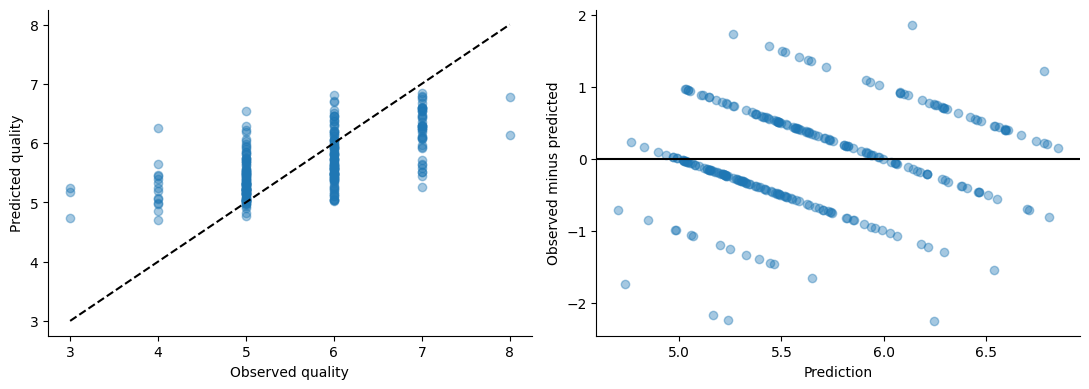

,feature,RMSE_increase,sd
10,alcohol,0.143070,0.012328
9,sulphates,0.086336,0.012903
1,volatile acidity,0.024290,0.008079
6,total sulfur dioxide,0.006629,0.004784
7,density,0.005561,0.002156
4,chlorides,0.004654,0.003780
5,free sulfur dioxide,0.003831,0.002879
0,fixed acidity,0.000446,0.000715
8,pH,0.000336,0.003257
2,citric acid,-0.001041,0.000849


In [7]:
def reg_metrics(y,p):
    return {'RMSE':root_mean_squared_error(y,p),'MAE':mean_absolute_error(y,p),'R2':r2_score(y,p),'within_one_point':float(np.mean(np.abs(np.asarray(y)-p)<=1))}
pv=model.predict(Xv);pt=model.predict(Xte);pb=baseline.predict(Xte)
metrics={'winner':winner,'validation':reg_metrics(yv,pv),'test':reg_metrics(yte,pt),'test_baseline':reg_metrics(yte,pb),'test_RMSE_CI95':bootstrap_ci(yte,pt,root_mean_squared_error)}
metrics['RMSE_relative_improvement']=1-metrics['test']['RMSE']/metrics['test_baseline']['RMSE'];metrics['proxy_gate_passed']=bool(metrics['RMSE_relative_improvement']>=.1)
save_json('metrics.json',metrics);display(pd.DataFrame({k:v for k,v in metrics.items() if isinstance(v,dict)}).T)
pred=pd.DataFrame({'source_row':df.index[te],'observed':yte.to_numpy(),'predicted':pt,'residual':yte.to_numpy()-pt});pred.to_csv(ART/'test_predictions.csv',index=False)
by=pred.groupby('observed').agg(n=('residual','size'),mean_residual=('residual','mean'),MAE=('residual',lambda x:abs(x).mean()));display(by);by.to_csv(ART/'quality_error.csv')
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].scatter(yte,pt,alpha=.4);axs[0].plot([3,8],[3,8],'k--');axs[0].set(xlabel='Observed quality',ylabel='Predicted quality');axs[1].scatter(pt,yte.to_numpy()-pt,alpha=.4);axs[1].axhline(0,color='k');axs[1].set(xlabel='Prediction',ylabel='Observed minus predicted');figure('test_residuals.png')
from sklearn.inspection import permutation_importance
imp=permutation_importance(model,Xv,yv,scoring='neg_root_mean_squared_error',n_repeats=5,random_state=SEED,n_jobs=1)
importance=pd.DataFrame({'feature':features,'RMSE_increase':imp.importances_mean,'sd':imp.importances_std}).sort_values('RMSE_increase',ascending=False);display(importance);importance.to_csv(ART/'validation_importance.csv',index=False)


## Delivery extension — scoring, monitoring, and final review
Save the fitted pipeline, a schema with expected feature order, and a sample batch. The local scorer returns continuous estimates. The lab owner should reject missing columns, invalid negative chemistry or nonnumeric values; measurements outside training ranges should be flagged for human review, not silently clipped. Score predictions are limited by the historical data and the regression formulation.

Proposed monitoring: examine input missingness and measurement ranges on each batch; review MAE monthly after tasting labels arrive. A 20% RMSE increase over this benchmark or a new measurement protocol triggers revalidation. Revert to the existing sensory workflow when monitoring fails. A new version must retain old artifacts and pass an independent holdout evaluation. This is an executable local handoff with a proposed operational plan, not a deployed commercial laboratory service.

In [8]:
joblib.dump(model,ART/'model.joblib');restored=joblib.load(ART/'model.joblib');np.testing.assert_allclose(restored.predict(Xte),pt)
Xte.iloc[:5].to_csv(ART/'sample_input.csv',index=False);pd.DataFrame({'predicted_quality':restored.predict(Xte.iloc[:5])}).to_csv(ART/'sample_output.csv',index=False)
sample=Xte.iloc[:5].copy();sample.iloc[0,0]=np.nan;assert np.isfinite(restored.predict(sample)).all()
save_json('verification.json',{'disjoint_feature_groups':True,'pipeline_roundtrip':True,'missing_measurement':True,'finite_predictions':bool(np.isfinite(pt).all()),'human_review_completed':False})
print('Saved pipeline. Proxy gate:',metrics['proxy_gate_passed'])


Saved pipeline. Proxy gate: True
